In [2]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_html("data-kejadian-pohon-tumbang-komponen-data.xls")[0]

data.head()

,periode_data,triwulan,bulan,wilayah,kecamatan,kelurahan,alamat,koordinat_x,koordinat_y,jumlah_pohon_tumbang,jumlah_sarana_rusak,jumlah_korban_meninggal,jumlah_korban_luka,nilai_kerugian
0,202506,2,5,KOTA ADM. JAKARTA TIMUR,MAKASAR,MAKASAR,JL. KERJA BAKTI GG.NANGKA NO.42 RT 01/RW 02,-6.275348,106.874377,1,1 KANOPI RUMAH,0,0,1000000
1,202506,2,5,KOTA ADM. JAKARTA UTARA,KOJA,TUGU UTARA,"JL. MUNDU, KEL. TUGU UTARA, KEC. KOJA",-6.117825,106.910426,1,1 KABEL PLN DAN AKSES JALAN,0,0,0
2,202506,2,5,KOTA ADM. JAKARTA UTARA,PENJARINGAN,PLUIT,"JL. MUARA KARANG RAYA, RT.04 RW. 012",-6.116983,106.781006,1,1 MOBIL,0,0,0
3,202506,2,5,KOTA ADM. JAKARTA UTARA,KELAPA GADING,KELAPA GADING BARAT,JLN. PULAU GALANG,-6.159677,106.889183,1,NaN,0,0,0
4,202506,2,5,KOTA ADM. JAKARTA UTARA,KELAPA GADING,KELAPA GADING TIMUR,"KOMPLEK PT. HII, JL. PASAR INPRES, RT.04/RW. 05",-6.176031,106.905457,1,NaN,0,0,0


In [3]:
print("Jumlah baris dan kolom:", data.shape)

Jumlah baris dan kolom: (309, 14)


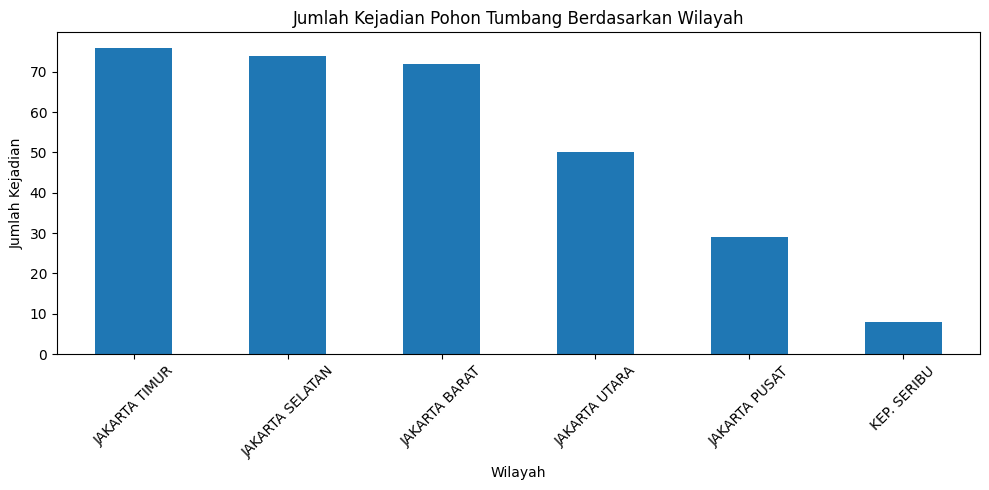

In [5]:
jumlah = data["wilayah"].value_counts()

jumlah.index = jumlah.index.str.replace(
    "KOTA ADM. ", "", regex=False
).str.replace("KAB. ADM. ", "", regex=False)

plt.figure(figsize=(10, 5))

jumlah.plot(kind="bar")

plt.title("Jumlah Kejadian Pohon Tumbang Berdasarkan Wilayah")
plt.xlabel("Wilayah")
plt.ylabel("Jumlah Kejadian")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("grafik_1_jumlah_kejadian.png", dpi=300)
plt.show()

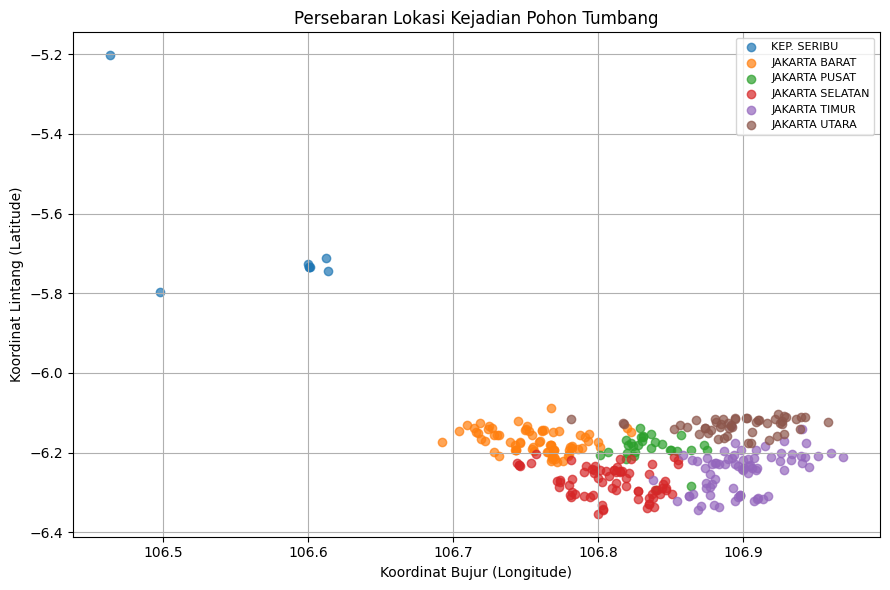

In [6]:
plt.figure(figsize=(9, 6))

for wilayah, kelompok in data.groupby("wilayah"):
    nama = wilayah.replace("KOTA ADM. ", "")
    nama = nama.replace("KAB. ADM. ", "")

    plt.scatter(
        kelompok["koordinat_y"],
        kelompok["koordinat_x"],
        label=nama,
        alpha=0.7
    )

plt.title("Persebaran Lokasi Kejadian Pohon Tumbang")
plt.xlabel("Koordinat Bujur (Longitude)")
plt.ylabel("Koordinat Lintang (Latitude)")
plt.legend(fontsize=8)
plt.grid(True)

plt.tight_layout()
plt.savefig("grafik_2_persebaran_lokasi.png", dpi=300)
plt.show()